# Predicting Falcon 9 first-stage landings

Can pre-launch information predict whether a Falcon 9 first stage will land? This notebook runs the leakage-controlled analysis in `spacex_analysis.py` and walks through its results.

The IBM lab fit a scaler on all 90 launches before splitting, tuned four classifiers with `GridSearchCV`, and scored them on an 18-launch holdout, where one misclassification moves accuracy by 5.6 points. Here every preprocessing step and hyperparameter search runs inside the training folds, and models are also tested on flights they never saw the future of.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import spacex_analysis as sa

launches = sa.load_launches()
print(f"{len(launches)} launches, {launches['Class'].sum()} landed ({launches['Class'].mean():.1%})")

90 launches, 60 landed (66.7%)


## Landing success rises with experience

Success climbs from under half of the first 30 flights to most of the last 30. A model that only learns this trend will look good under shuffled cross-validation.

In [2]:
launches.groupby(pd.cut(launches['FlightNumber'], [0, 30, 60, 90], labels=['1-30', '31-60', '61-90']), observed=True)['Class'].agg(landing_rate='mean', launches='size')

,landing_rate,launches
FlightNumber,,
1-30,0.433333,30
31-60,0.733333,30
61-90,0.833333,30


## Two course features use post-launch information

`ReusedCount` comes from the SpaceX API's core record, which stores the booster's lifetime reuse count at the time the data was pulled. A booster that flies again later must have been recovered, so for those launches the feature reveals the label. `Serial` one-hot columns carry the same signal by identity. The analysis drops both and keeps only pre-launch fields: flight number, payload mass, orbit, launch site, landing pad, booster block, the core's flight count, and whether legs, grid fins and a reused core were used.

In [3]:
raw = pd.read_csv(ROOT / 'data' / 'raw' / 'dataset_part_2.csv')
flies_again = raw.duplicated('Serial', keep='last')
pd.crosstab([raw['ReusedCount'] > 0, flies_again], raw['Class'], rownames=['ReusedCount > 0', 'booster flies again'], colnames=['landed'])

landed                                0   1
ReusedCount > 0 booster flies again        
False           False                22   8
True            False                 8  15
                True                  0  37

## Run the analysis

Nested cross-validation: 10 repeats of stratified 5-fold outer CV, with a 5-fold grid search inside each training fold. The one-step-ahead evaluation trains on flights 1 to t and predicts flight t + 1 for t = 40 to 89. This takes about two minutes.

In [4]:
metrics = sa.run(ROOT / 'outputs')
comparison = pd.read_csv(ROOT / 'outputs' / 'model_comparison.csv')
(comparison[comparison.metric.isin(['roc_auc', 'balanced_accuracy'])]
 .pivot_table(index='model', columns=['feature_set', 'metric'], values='mean')
 .round(3))

feature_set         course_with_leaky_columns                 prelaunch  \
metric                      balanced_accuracy roc_auc balanced_accuracy   
model                                                                     
decision_tree                           0.782   0.836             0.821   
knn                                     0.608   0.752             0.773   
logistic_regression                     0.751   0.824             0.725   
majority_baseline                       0.500   0.500             0.500   
svm_rbf                                 0.788   0.766             0.773   

feature_set                  
metric              roc_auc  
model                        
decision_tree         0.826  
knn                   0.805  
logistic_regression   0.821  
majority_baseline     0.500  
svm_rbf               0.856

In [5]:
pd.DataFrame(metrics['one_step_ahead_prelaunch']).T[['roc_auc', 'balanced_accuracy', 'accuracy', 'brier']].round(3)

,roc_auc,balanced_accuracy,accuracy,brier
majority_baseline,0.568,0.500,0.78,0.204
logistic_regression,0.667,0.545,0.80,0.157
svm_rbf,0.566,0.669,0.84,0.138
decision_tree,0.538,0.618,0.76,0.214
knn,0.709,0.545,0.80,0.147


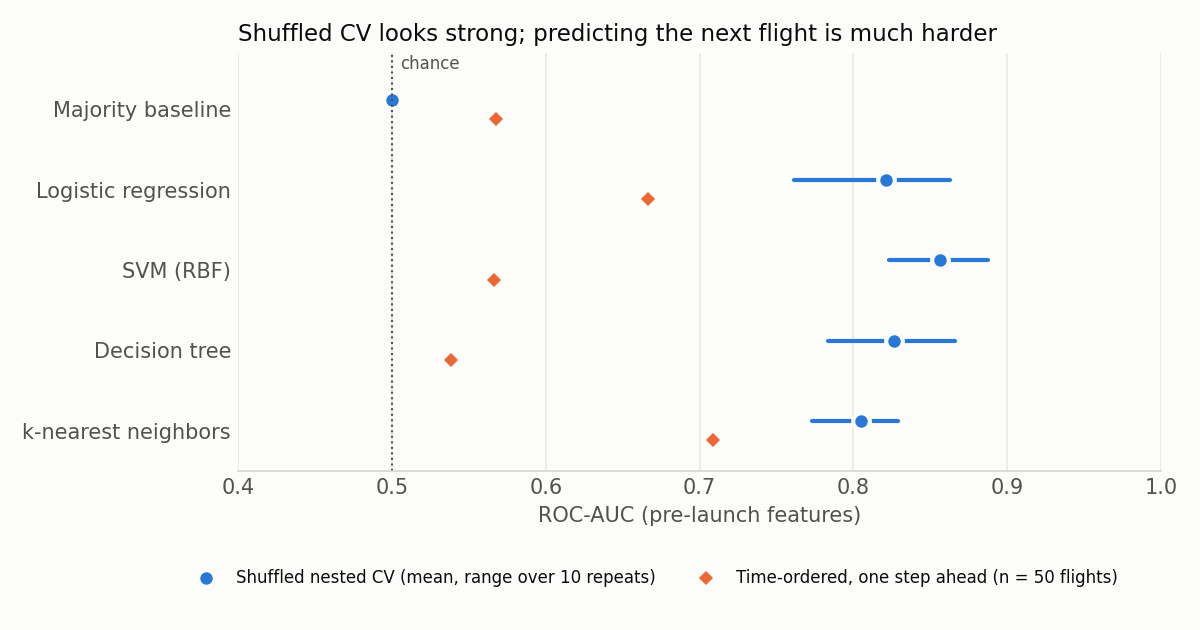

In [6]:
Image(filename=str(ROOT / 'outputs' / 'figures' / 'model_comparison.png'))

## Reading the results

- Under shuffled nested CV, every pre-launch model clears the majority baseline (ROC-AUC 0.5), and the RBF SVM scores highest.
- Dropping the leaky columns costs nothing. On the course's 83-column table, logistic regression and the decision tree land within 0.01 AUC of their pre-launch versions, and the SVM and k-NN score lower.
- Predicting the next flight from past flights alone is much harder. 39 of the last 50 launches landed, so always predicting "landed" is already 78% accurate. The SVM reaches 84% accuracy and a lower Brier score, but ROC-AUC on those 50 flights is far below the shuffled-CV estimate.
- With 90 launches, model differences of a few hundredths of AUC are within run-to-run noise.